# Block 4. Temporal patterns and burn calendar

Owner: Vicente (M3). Plan: `docs/eda-plan.md`, block 4. Findings and rules for the API: `docs/findings/04-calendar.md`.
Input: the hotspot table (C1) and `quality_flags.parquet` from `01_quality.ipynb` (filter decisions). Output: `NASA_Data_Sources/processed/calendar/monthly_by_region.parquet`.

**What is not here yet.** The harmonized dataset (contract C2, module M2) does not exist yet, so the calendar statistics are computed **per sensor**:
MODIS (Terra and Aqua) and VIIRS (Suomi-NPP, NOAA-20). Every function takes a table of counts, so the same code runs on the harmonized counts when M2 publishes them
(section 4.8 shows what to change). Nothing here claims a harmonized trend.

Units. `rows` = hotspots after the quality filter. `fire_days` = distinct (0.25 degree cell, `burn_date`) pairs with at least one hotspot; it counts "days with fire" and is less sensitive
to the VIIRS / MODIS gap in points per fire. The day key is `burn_date`. Complete data end on **2026-11-13**.

In [1]:
from pathlib import Path
import datetime as dt
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy import stats

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False})

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').exists())
DATA = ROOT / 'NASA_Data_Sources'
HOT = (DATA / 'processed/hotspots').as_posix()
FLAGS = DATA / 'processed/quality/quality_flags.parquet'
OUT = DATA / 'processed/calendar'; OUT.mkdir(parents=True, exist_ok=True)
assert FLAGS.exists(), 'run notebooks/01_quality.ipynb first'

con = duckdb.connect()
con.execute("SET TimeZone='UTC'")
try: con.execute("SET enable_progress_bar=false")
except Exception: pass
SRC = f"read_parquet('{HOT}/*/*.parquet', hive_partitioning=true)"
cols = [r[0] for r in con.execute(f"DESCRIBE SELECT * FROM {SRC}").fetchall()]
burn = "" if 'burn_date' in cols else ", CAST((acq_datetime AT TIME ZONE 'UTC') + to_seconds(CAST(round(longitude/15*3600 - 6*3600) AS BIGINT)) AS DATE) AS burn_date"
con.execute(f"""CREATE VIEW h AS SELECT *, CAST(acq_datetime AT TIME ZONE 'UTC' AS TIMESTAMP) AS ts {burn} FROM {SRC}""")
def q(sql): return con.sql(sql).df()

LAST_DAY = '2026-11-13'
# Filtered rows (recommended filter of block 1) with region (admin1 or the nearest region within 5 km) and a 0.25 degree cell.
con.execute(f"""CREATE TABLE base AS
SELECT h.satellite, h.instrument, h.burn_date, h.acq_date, h.ts, h.latitude, h.longitude, h.country, coalesce(h.admin1, f.admin1_fixed) AS region,
       h.processing, CAST(floor(h.latitude / 0.25) AS INT) cy, CAST(floor(h.longitude / 0.25) AS INT) cx
FROM h JOIN read_parquet('{FLAGS.as_posix()}') f USING (satellite, acq_datetime, latitude, longitude)
WHERE f.keep AND h.burn_date <= DATE '{LAST_DAY}'""")
print(q('SELECT count(*) filtered_rows, count(*) FILTER (WHERE region IS NULL) without_region FROM base').to_dict('records'))

[{'filtered_rows': 7000515, 'without_region': 0}]


## Monthly aggregates (the table the calendar reads)

One row per region, year, month and satellite: `rows`, `fire_days` and `nrt_rows` (rows of provisional data). This is the file saved for the API.

In [2]:
mon = q('''SELECT country, region, year(burn_date) y, month(burn_date) mo, satellite, instrument,
  count(*) rows_, count(DISTINCT (cy, cx, burn_date)) fire_days, count(*) FILTER (WHERE processing = 'NRT') nrt_rows
  FROM base WHERE region IS NOT NULL GROUP BY ALL''')
mon.to_parquet(OUT / 'monthly_by_region.parquet', index=False)
print(len(mon), 'rows saved to', (OUT / 'monthly_by_region.parquet').relative_to(ROOT))
print('Regions:', mon.region.nunique(), '| satellites:', sorted(mon.satellite.unique()))
nat = mon.groupby(['y', 'mo', 'satellite'], as_index=False)[['rows_', 'fire_days']].sum()   # fire_days summed over regions is exact: cells do not cross regions
tot = nat.groupby('satellite').agg(rows=('rows_', 'sum'))
display(tot)

31096 rows saved to NASA_Data_Sources\processed\calendar\monthly_by_region.parquet
Regions: 52 | satellites: ['Aqua', 'NOAA-20', 'NOAA-21', 'Suomi-NPP', 'Terra']


,rows
satellite,
Aqua,1134676
NOAA-20,1755958
NOAA-21,521438
Suomi-NPP,2924881
Terra,663562


## 4.1 Year by month heatmaps

Counts use a log colour scale (a few peak months are 100 times the typical month) and a colour-blind-safe sequential ramp (cividis). The same numbers are shown in calendar order
and in season order (July to June, the CONAF convention). Provisional months (VIIRS: August to October 2026, MODIS: September and October 2026) carry a dot. November 2026 has only 13 days and is left blank.

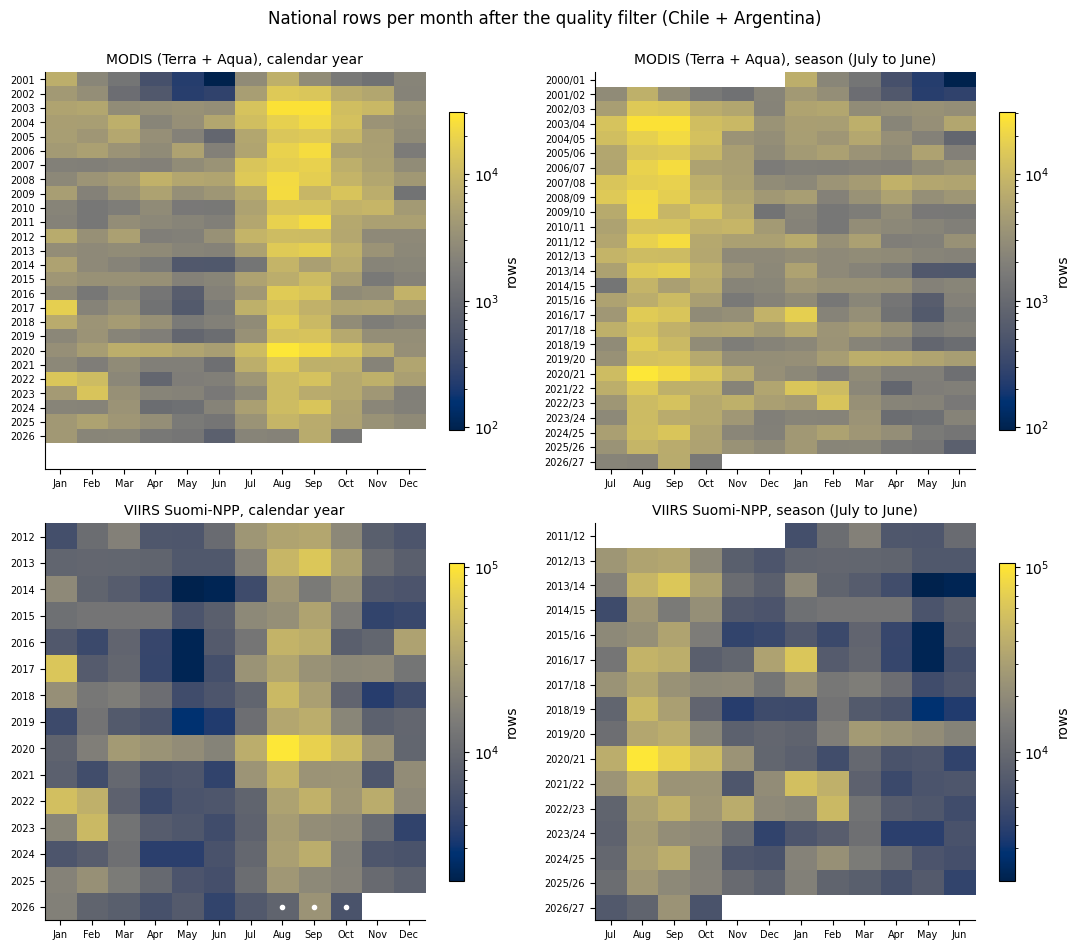

In [3]:
MN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
def grid(df, value='rows_', order='calendar'):
    d = df.groupby(['y', 'mo'], as_index=False)[value].sum()
    d = d[~((d.y == 2026) & (d.mo == 11))]   # November 2026 has 13 days: left blank, never shown next to complete months
    if order == 'season':
        start = np.where(d.mo >= 7, d.y, d.y - 1); d['season'] = [f'{a}/{str(a + 1)[2:]}' for a in start]; d['pos'] = (d.mo - 7) % 12
        return d.pivot(index='season', columns='pos', values=value).reindex(columns=range(12))
    return d.pivot(index='y', columns='mo', values=value).reindex(columns=range(1, 13))

def heat(ax, g, title, labels, vmax=None):
    g = g.where(g > 0)
    im = ax.imshow(g.values, aspect='auto', cmap='cividis', norm=LogNorm(vmin=max(1, np.nanmin(g.values)), vmax=vmax or np.nanmax(g.values)))
    ax.set_xticks(range(12)); ax.set_xticklabels(labels, fontsize=7); ax.set_yticks(range(len(g.index))); ax.set_yticklabels(g.index, fontsize=7); ax.set_title(title, fontsize=10)
    return im

modis = nat[nat.satellite.isin(['Terra', 'Aqua'])]
viirs = nat[nat.satellite == 'Suomi-NPP']
fig, axs = plt.subplots(2, 2, figsize=(11, 9.5))
for r, (name, df, y0) in enumerate([('MODIS (Terra + Aqua)', modis, 2001), ('VIIRS Suomi-NPP', viirs, 2012)]):
    g = grid(df[df.y >= y0], order='calendar'); im = heat(axs[r, 0], g, f'{name}, calendar year', MN); plt.colorbar(im, ax=axs[r, 0], shrink=.8, label='rows')
    gs = grid(df[df.y >= y0], order='season'); im = heat(axs[r, 1], gs, f'{name}, season (July to June)', MN[6:] + MN[:6]); plt.colorbar(im, ax=axs[r, 1], shrink=.8, label='rows')
# dots for provisional months of 2026 in the calendar-order panels
for r in range(2):
    ys = list(grid((modis if r == 0 else viirs), order='calendar').index)
    for mo in range(9 if r == 0 else 8, 11): axs[r, 0].plot(mo - 1, ys.index(2026), marker='o', ms=3, color='white')
fig.suptitle('National rows per month after the quality filter (Chile + Argentina)', y=.995); plt.tight_layout(); plt.show()

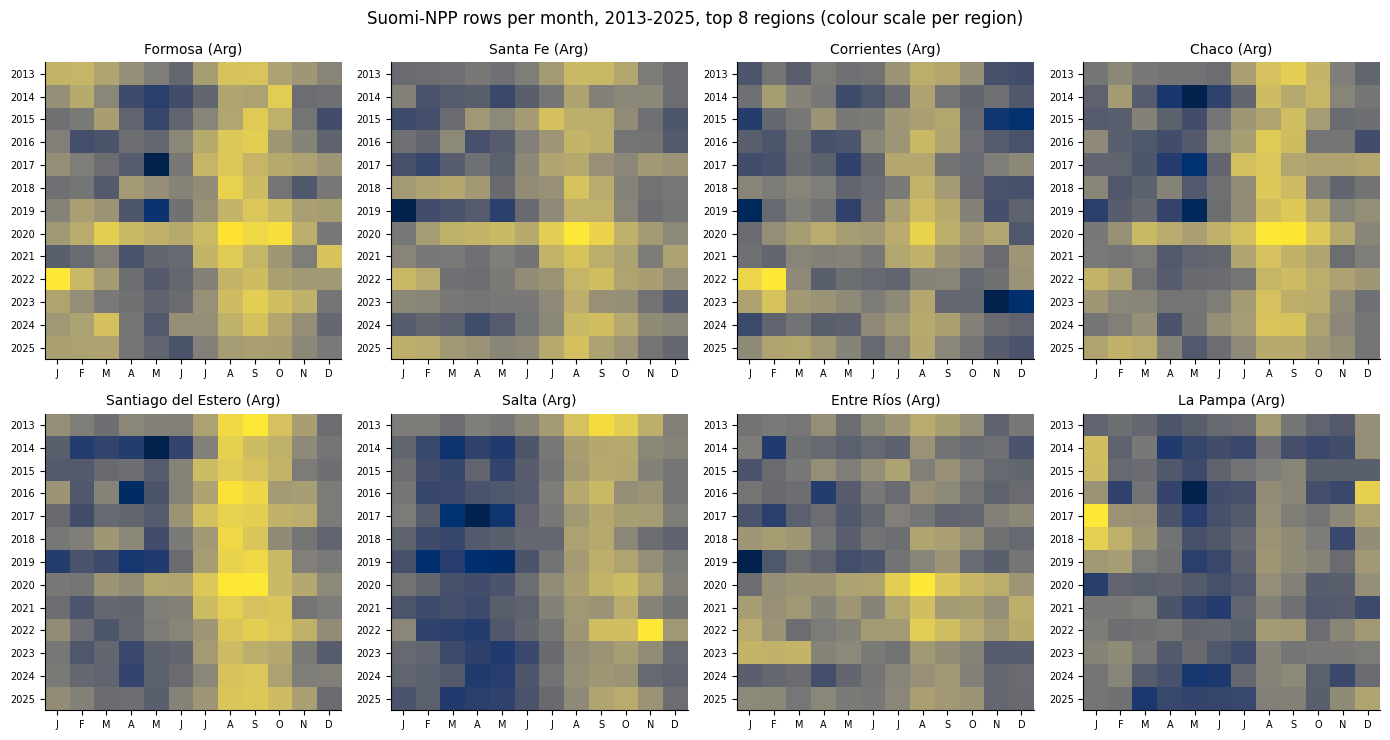

                                 rows
country   region                     
Argentina Formosa              396963
          Santa Fe             376987
          Corrientes           289612
          Chaco                255051
          Santiago del Estero  249957
          Salta                217796
          Entre Ríos           125547
          La Pampa              87355


In [4]:
# Regions with the most VIIRS rows: Suomi-NPP year by month, own colour scale per region.
top = mon[mon.satellite == 'Suomi-NPP'].groupby(['country', 'region']).rows_.sum().sort_values(ascending=False).head(8)
fig, axs = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, ((c, rg), _) in zip(axs.ravel(), top.items()):
    g = grid(mon[(mon.satellite == 'Suomi-NPP') & (mon.region == rg) & (mon.y.between(2013, 2025))], order='calendar')
    heat(ax, g, f'{rg[:26]} ({c[:3]})', [m[0] for m in MN])
fig.suptitle('Suomi-NPP rows per month, 2013-2025, top 8 regions (colour scale per region)'); plt.tight_layout(); plt.show()
print(top.rename('rows').to_frame())

**Reading.** The national picture is northern Argentina: a band every August and September, and **2020** as the strongest year in both sensors. Outside that band the calendar shows the central-south Chile summers
(January 2017, February 2023) and the Corrientes fires of January and February 2022. MODIS (2001-2026) and VIIRS (2012-2026) have different levels (VIIRS is shown on its own scale), so the two panels must not be read as one series.
The darkest cells in 2001 are the Terra gap of 15 June to 2 July 2001 (block 1.1), and the months before Aqua (2002-07) have Terra only. The season layout (July to June) is the natural unit for Chile, whose fire season runs from December to March.

## 4.2 Seasonality per region

On Suomi-NPP, 2013-2025 (13 complete years). For each region: the **peak month**, the share of the year in the peak month, and the **season length**: the shortest run of consecutive months
(circular, so it can cross the new year) that holds at least 80% of the rows. `peak stable` is the share of years in which the peak month is the long-run peak month or a neighbour.

In [5]:
v = mon[(mon.satellite == 'Suomi-NPP') & mon.y.between(2013, 2025)]
rows = []
for (c, rg), g in v.groupby(['country', 'region']):
    m = g.groupby('mo').rows_.sum().reindex(range(1, 13), fill_value=0); n = m.sum()
    if n < 3000: continue
    share = m / n; peak = int(share.idxmax())
    best = next(L for L in range(1, 13) if any(share.iloc[[(s + k) % 12 for k in range(L)]].sum() >= .8 for s in range(12)))
    ym = g.pivot_table(index='y', columns='mo', values='rows_', aggfunc='sum').reindex(columns=range(1, 13), fill_value=0)
    ypeak = ym.idxmax(axis=1); stable = np.mean([min((p - peak) % 12, (peak - p) % 12) <= 1 for p in ypeak])
    rows.append(dict(country=c, region=rg, rows=int(n), peak_month=MN[peak - 1], peak_share_pct=round(100 * share.max(), 1), months_for_80pct=best, peak_stable_pct=round(100 * stable), **{MN[i]: share.iloc[i] for i in range(12)}))
seas = pd.DataFrame(rows).sort_values('rows', ascending=False)
display(seas.drop(columns=MN).head(24).reset_index(drop=True))

,country,region,rows,peak_month,peak_share_pct,months_for_80pct,peak_stable_pct
0,Argentina,Formosa,358978,Sep,22.4,7,77
1,Argentina,Santa Fe,351825,Aug,25.2,8,100
2,Argentina,Corrientes,256076,Aug,24.2,8,85
3,Argentina,Chaco,230509,Aug,27.2,6,92
4,Argentina,Santiago del Estero,220876,Aug,27.4,5,100
5,Argentina,Salta,191751,Sep,28.0,4,92
6,Argentina,Entre Ríos,115795,Aug,29.1,8,85
7,Argentina,La Pampa,85276,Jan,43.2,6,62
8,Argentina,Buenos Aires,77023,Aug,16.1,8,46
9,Chile,Región de La Araucanía,73612,Mar,32.9,4,92


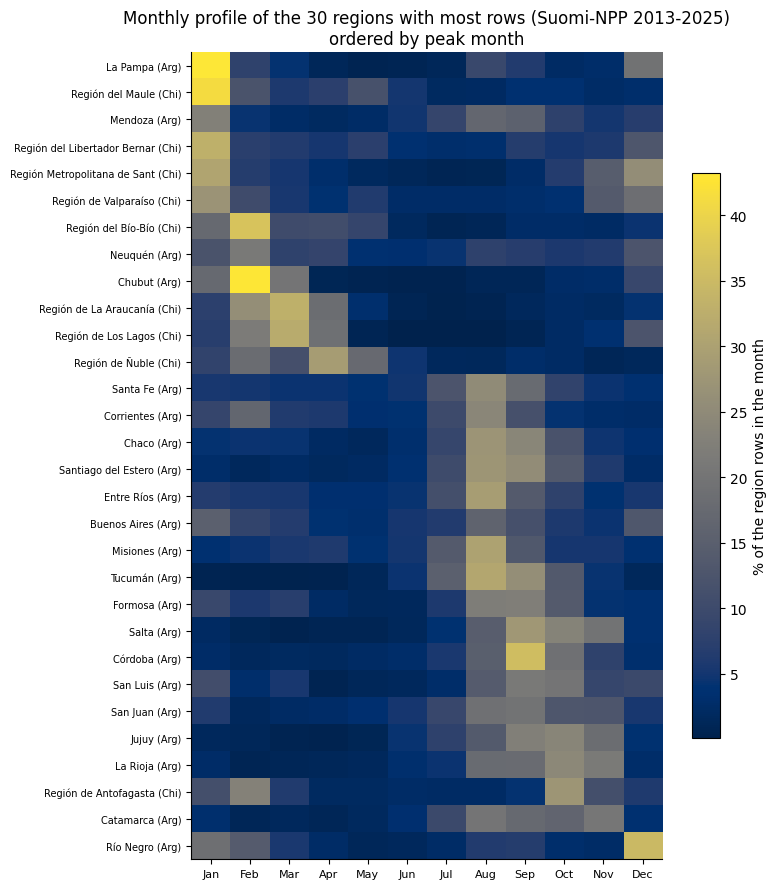

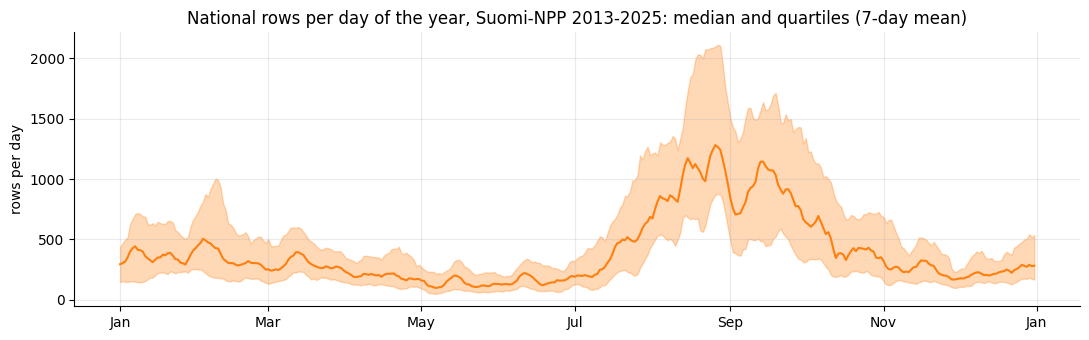

In [6]:
sh = seas.head(30).copy(); sh['pk'] = [MN.index(p) for p in sh.peak_month]
sh = sh.sort_values(['pk', 'rows'], ascending=[True, False])
fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(sh[MN].values * 100, aspect='auto', cmap='cividis'); plt.colorbar(im, label='% of the region rows in the month', shrink=.7)
ax.set_xticks(range(12)); ax.set_xticklabels(MN, fontsize=8); ax.set_yticks(range(len(sh))); ax.set_yticklabels([f"{r[:28]} ({c[:3]})" for r, c in zip(sh.region, sh.country)], fontsize=7)
ax.set_title('Monthly profile of the 30 regions with most rows (Suomi-NPP 2013-2025)\nordered by peak month'); plt.tight_layout(); plt.show()

# National daily climatology on burn_date, Suomi-NPP 2013-2025 (7-day running mean of the median)
dc = q('''SELECT burn_date, count(*) n FROM base WHERE satellite = 'Suomi-NPP' AND year(burn_date) BETWEEN 2013 AND 2025 GROUP BY 1''')
dc['d'] = pd.to_datetime(dc.burn_date); dc = dc[~((dc.d.dt.month == 2) & (dc.d.dt.day == 29))]
dc['doy'] = dc.d.dt.strftime('%m-%d')
band = dc.groupby('doy').n.quantile([.25, .5, .75]).unstack().rolling(7, center=True, min_periods=1).mean()
x = pd.to_datetime('2001-' + band.index)
fig, ax = plt.subplots(figsize=(11, 3.5)); ax.fill_between(x, band[.25], band[.75], alpha=.3, color='tab:orange'); ax.plot(x, band[.5], color='tab:orange', lw=1.5)
ax.set(title='National rows per day of the year, Suomi-NPP 2013-2025: median and quartiles (7-day mean)', ylabel='rows per day'); ax.grid(alpha=.25)
import matplotlib.dates as mdates; ax.xaxis.set_major_formatter(mdates.DateFormatter('%b')); plt.tight_layout(); plt.show()

**Reading.**

- **Northern Argentina** (Formosa, Santa Fe, Corrientes, Chaco, Santiago del Estero, Salta, Entre Rios) peaks in **August or September** with 22 to 29% of the year in the peak month and 4 to 8 months to hold 80% of the rows.
  The peak month is stable: 77 to 100% of the years peak within a month of the long-run peak (Santiago del Estero, Santa Fe and Tucuman: every year).
- **Central-south Chile** peaks in summer, with a sharper season: Maule in January (41%), Biobio in February (37%), La Araucania in March (33%), Nuble in April (29%).
- **Patagonia and the Pampas** are short and sharp: Chubut in February (43%, 3 months for 80%), La Pampa in January (43%), Rio Negro in December (35%). Cordoba peaks in September (36%).
- **Unstable peaks:** Buenos Aires (46% of years near the peak month), Mendoza and Neuquen (38%). Their yearly peak moves, so a "typical month" is weak information there and the calendar should show the whole profile.
- Nationally the daily median has a main peak from mid-August to mid-September (about 1,200 rows per day) and a secondary bump in January and February (about 450 rows per day, the Chilean and Patagonian season).
  The quartile band is widest in the peak: the intensity of a season changes a lot from year to year while its timing hardly does.

These profiles are the input to the regime grouping of block 5.2. A calendar that colours one scale for the whole country would show only northern Argentina: it needs a scale per region (or the percentile).

## 4.3 Monthly median, percentiles and anomalies

For a region, month and year, compared with the same month in the **other** years of a reference period (leave-one-out, so the year being judged is not in its own reference):

- `ratio` = (x + 1) / (median + 1). The pseudo-count keeps the ratio finite when the median is 0 and stops 1 hotspot against 0 from looking like an infinite anomaly.
- `percentile` = share of reference years below x (ties count half). It does not depend on the scale of the counts and is the number we show first.
- `reliable` is false when the reference median is below `MIN_MEDIAN`: the history is too thin to colour the cell.

`MIN_MEDIAN` is chosen with the table below. It shows, by size of the reference median, how far the log2 ratio of an ordinary year spreads (interquartile range, in powers of 2).
With a very small median the pseudo-count dominates and the spread is largest; from a median of 3 upward the spread settles near 1.5 (a factor 2.8 between the quartiles of ordinary years).
We set the threshold at 10: there, the pure counting noise of a Poisson count (1 / sqrt(10), about 32%) is well below that ordinary year-to-year spread, so a colour means something.

In [7]:
def anomaly_table(df, value='rows_', ref_years=range(2013, 2026), min_n=8):
    # df: columns region, y, mo, value (one satellite or one harmonized series). Leave-one-out reference.
    p = df.pivot_table(index=['region', 'mo'], columns='y', values=value, aggfunc='sum').reindex(columns=sorted(set(df.y) | set(ref_years))).fillna(0)
    ref = [y for y in ref_years if y in p.columns]; out = []
    for y in p.columns:
        others = [r for r in ref if r != y]
        base_ = p[others].values; x = p[y].values
        med = np.median(base_, axis=1)
        below = (base_ < x[:, None]).sum(axis=1) + .5 * (base_ == x[:, None]).sum(axis=1)
        out.append(pd.DataFrame({'region': p.index.get_level_values(0), 'mo': p.index.get_level_values(1), 'y': y, 'value': x, 'median': med,
                                 'ratio': (x + 1) / (med + 1), 'percentile': below / len(others)}))
    a = pd.concat(out, ignore_index=True)
    a['log2_ratio'] = np.log2(a.ratio)
    return a

vv = mon[(mon.satellite == 'Suomi-NPP')]
an = anomaly_table(vv)
an_ref = an[an.y.between(2013, 2025)]
bins = [0, 1, 3, 10, 30, 100, 300, 1000, 1e9]
an_ref = an_ref.assign(med_bin=pd.cut(an_ref['median'], bins, right=False))
spread = an_ref.groupby('med_bin', observed=True).agg(cells=('ratio', 'size'), iqr_log2=('log2_ratio', lambda s: s.quantile(.75) - s.quantile(.25)), p90_abs_log2=('log2_ratio', lambda s: s.abs().quantile(.9)))
display(spread.round(2))

,cells,iqr_log2,p90_abs_log2
med_bin,,,
"[0.0, 1.0)",644,0.00,1.00
"[1.0, 3.0)",320,2.22,2.18
"[3.0, 10.0)",724,1.54,2.00
"[10.0, 30.0)",997,1.52,2.11
"[30.0, 100.0)",1261,1.59,2.06
"[100.0, 300.0)",1346,1.50,2.25
"[300.0, 1000.0)",903,1.64,2.41
"[1000.0, 1000000000.0)",396,1.15,1.86


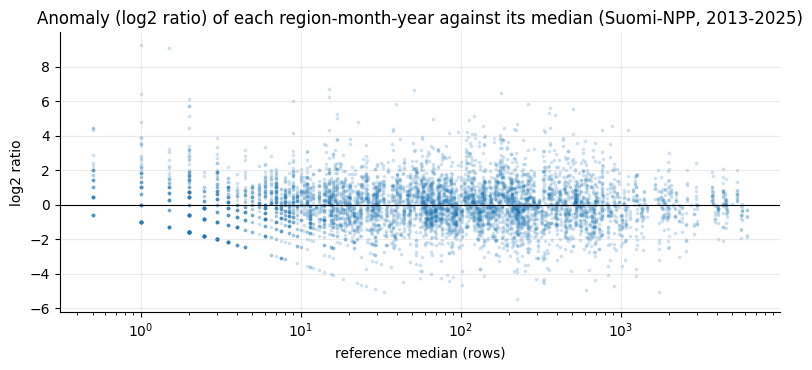

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
s = an_ref[an_ref['median'] > 0]
ax.scatter(s['median'], s.log2_ratio, s=3, alpha=.15); ax.set_xscale('log'); ax.axhline(0, color='k', lw=.8)
ax.set(title='Anomaly (log2 ratio) of each region-month-year against its median (Suomi-NPP, 2013-2025)', xlabel='reference median (rows)', ylabel='log2 ratio'); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

In [9]:
MIN_MEDIAN = 10   # counting noise at 10 rows is about 32%, well below the ordinary spread of 1.5 powers of 2 (table above)
an['reliable'] = an['median'] >= MIN_MEDIAN
print('Share of region-months with a reliable reference (median >= %d):' % MIN_MEDIAN, round(100 * an[an.y.between(2013, 2025)].groupby(['region', 'mo']).reliable.first().mean(), 1), '%')
print('Share of rows that sit in reliable region-months:', round(100 * an[an.y.between(2013, 2025) & an.reliable].value.sum() / an[an.y.between(2013, 2025)].value.sum(), 1), '%')

# Sanity check on well-known events (not a case study: block 6 belongs to M5). Region-month, Suomi-NPP.
checks = [('Valpara', 2024, 2, 'Valparaiso fires, Feb 2024'), ('Biob', 2023, 2, 'central-south Chile fires, Feb 2023'), ('uble', 2023, 2, 'central-south Chile fires, Feb 2023'),
          ('Araucan', 2023, 2, 'central-south Chile fires, Feb 2023'), ('rdoba', 2024, 9, 'Cordoba fires, Sep 2024'), ('Corrientes', 2022, 1, 'Corrientes fires, Jan 2022'), ('Corrientes', 2022, 2, 'Corrientes fires, Feb 2022')]
r = []
for pat, y, mo, label in checks:
    d = an[an.region.str.contains(pat) & (an.y == y) & (an.mo == mo)]
    for _, row in d.iterrows(): r.append(dict(event=label, region=row.region, year=y, month=MN[mo - 1], rows=int(row.value), median=row['median'], ratio=round(row.ratio, 1), percentile=round(row.percentile, 2), reliable=row.reliable))
display(pd.DataFrame(r))

Share of region-months with a reliable reference (median >= 10): 74.0 %
Share of rows that sit in reliable region-months: 99.6 %


,event,region,year,month,rows,median,ratio,percentile,reliable
0,"Valparaiso fires, Feb 2024",Región de Valparaíso,2024,Feb,435,37.0,11.5,1.00,True
1,"central-south Chile fires, Feb 2023",Región de Ñuble,2023,Feb,5165,51.5,98.4,1.00,True
2,"central-south Chile fires, Feb 2023",Región de La Araucanía,2023,Feb,7776,599.5,13.0,1.00,True
3,"Cordoba fires, Sep 2024",Córdoba,2024,Sep,4553,436.0,10.4,0.83,True
4,"Corrientes fires, Jan 2022",Corrientes,2022,Jan,14346,358.5,39.9,1.00,True
5,"Corrientes fires, Feb 2022",Corrientes,2022,Feb,23393,505.0,46.2,1.00,True


**Reading.**

- With a very small reference median the pseudo-count dominates the ratio. From a median of 3 upward the spread of the log2 ratio is stable near 1.5 (1.2 to 1.6; ordinary years differ by a factor of about 2.8 between the quartiles).
  `MIN_MEDIAN = 10` keeps **99.6% of the rows** but only 74% of region-months: the cells left out are small regions in their quiet months, where "anomaly" would be noise. For them the app should show the count and no colour.
- The ratio and the percentile separate the known events from ordinary years (Suomi-NPP, reference 2013-2025 without the year judged): Valparaiso in February 2024 had 435 rows against a median of 37 (ratio 11.5, percentile 1.00);
  Nuble in February 2023, 5,165 against 52 (98 times, percentile 1.00); La Araucania in February 2023, 7,776 against 600 (13 times); Corrientes in January and February 2022, 14,346 and 23,393 against 359 and 505 (40 and 46 times, percentile 1.00).
- Cordoba in September 2024 had 4,553 rows against a median of 436 (10 times) but percentile 0.83, because two reference years had more. The ratio says "very large", the percentile says "not the largest": the app should give both.
- These checks only show that the calendar flags what is known. They are not a validation of the harmonization and not a replacement for block 6.

## 4.4 The current month against the same days of other years

November 2026 has 13 complete days. We compare days 1 to 13 of November in every earlier year. Suomi-NPP ended on 2026-11-02, so the comparison uses **one satellite that is present in every year**:
NOAA-20 (2019-2025 for a full 1 to 13 November, 2018 started in April) and Aqua (2003-2025). The 2026 numbers are NRT (provisional).

In [10]:
cut = int(q(f"SELECT day(max(burn_date)) d FROM base WHERE satellite = 'NOAA-20'").d[0])
print('days compared: 1 to', cut, 'of November')
def same_days(sat, y0, y1, level='country'):
    d = q(f'''SELECT year(burn_date) y, {level}, count(*) rows_, count(DISTINCT (cy, cx, burn_date)) fire_days, count(*) FILTER (WHERE processing = 'NRT') nrt
      FROM base WHERE satellite = '{sat}' AND month(burn_date) = 11 AND day(burn_date) <= {cut} AND year(burn_date) BETWEEN {y0} AND 2026 AND {level} IS NOT NULL GROUP BY ALL''')
    return d
def compare(sat, y0, level='country', value='rows_'):
    d = same_days(sat, y0, 2026, level)
    p = d.pivot_table(index=level, columns='y', values=value, fill_value=0)
    ref = p[[c for c in p.columns if c < 2026]]
    out = pd.DataFrame({'2026': p[2026], 'median': ref.median(axis=1), 'min': ref.min(axis=1), 'max': ref.max(axis=1)})
    out['ratio'] = ((out['2026'] + 1) / (out['median'] + 1)).round(2)
    out['percentile'] = [((ref.loc[i] < p.loc[i, 2026]).sum() + .5 * (ref.loc[i] == p.loc[i, 2026]).sum()) / ref.shape[1] for i in out.index]
    out['percentile'] = out['percentile'].round(2)
    return out, p
rows = []
for sat, y0 in [('NOAA-20', 2019), ('Aqua', 2003)]:
    for val in ['rows_', 'fire_days']:
        t, p = compare(sat, y0, 'country', val); t.insert(0, 'satellite', sat); t.insert(1, 'metric', val); rows.append(t.reset_index())
display(pd.concat(rows, ignore_index=True))

days compared: 1 to 13 of November


,country,satellite,metric,2026,median,min,max,ratio,percentile
0,Argentina,NOAA-20,rows_,6349.0,3064.0,2234.0,19181.0,2.07,0.57
1,Chile,NOAA-20,rows_,543.0,382.0,335.0,581.0,1.42,0.86
2,Argentina,NOAA-20,fire_days,1621.0,973.0,869.0,2784.0,1.67,0.71
3,Chile,NOAA-20,fire_days,208.0,153.0,103.0,175.0,1.36,1.00
4,Argentina,Aqua,rows_,1356.0,959.0,244.0,3446.0,1.41,0.70
5,Chile,Aqua,rows_,28.0,59.0,21.0,132.0,0.48,0.04
6,Argentina,Aqua,fire_days,670.0,449.0,162.0,1243.0,1.49,0.78
7,Chile,Aqua,fire_days,23.0,40.0,13.0,69.0,0.59,0.09


Regions, NOAA-20, 1-13 November (only regions with a median or a 2026 count of at least 10 rows):


,2026,median,min,max,ratio,percentile
region,,,,,,
Formosa,2014.0,588.0,195.0,3232.0,3.42,0.86
Chaco,1090.0,315.0,192.0,1135.0,3.45,0.86
Santiago del Estero,1069.0,368.0,170.0,1210.0,2.90,0.71
Salta,583.0,611.0,117.0,12175.0,0.95,0.43
Santa Fe,449.0,405.0,105.0,1671.0,1.11,0.57
Corrientes,193.0,211.0,20.0,1051.0,0.92,0.43
Neuquén,145.0,56.0,31.0,98.0,2.56,1.00
Mendoza,123.0,92.0,33.0,128.0,1.33,0.86
Entre Ríos,109.0,67.0,16.0,894.0,1.62,0.57


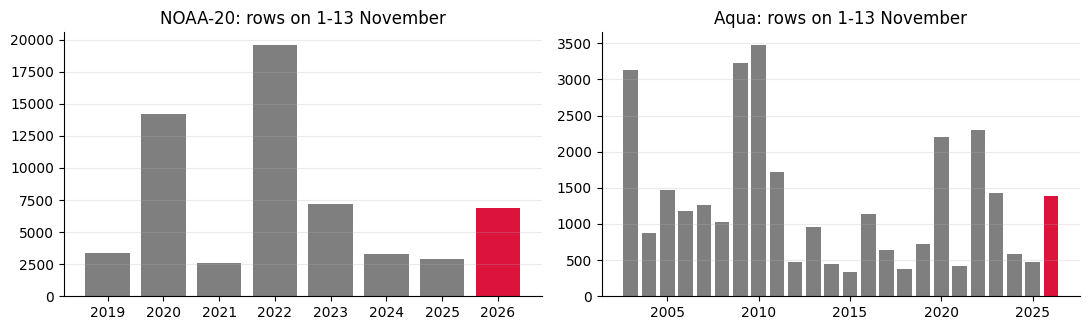

In [11]:
t, p = compare('NOAA-20', 2019, 'region', 'rows_')
t = t[(t['median'] >= 10) | (t['2026'] >= 10)].sort_values('2026', ascending=False)
print('Regions, NOAA-20, 1-%d November (only regions with a median or a 2026 count of at least 10 rows):' % cut); display(t.head(12))
nat_p = same_days('NOAA-20', 2019, 'country').groupby('y').rows_.sum(); nat_a = same_days('Aqua', 2003, 'country').groupby('y').rows_.sum()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, s, n in [(ax[0], nat_p, 'NOAA-20'), (ax[1], nat_a, 'Aqua')]:
    a.bar(s.index, s.values, color=['crimson' if y == 2026 else 'tab:gray' for y in s.index]); a.set(title=f'{n}: rows on 1-{cut} November'); a.grid(alpha=.25, axis='y')
plt.tight_layout(); plt.show()

**Reading.**

- NOAA-20, 1 to 13 November: northern Argentina is at **2.1 times the median** (6,349 rows against 3,064; percentile 0.57, because 2020 had 19,181 and the spread across the 7 reference years is wide);
  Formosa and Chaco are at 3.4 times, Santiago del Estero at 2.9 times (percentile 0.71 to 0.86). Salta, Santa Fe and Corrientes are at the median.
- Chile: NOAA-20 says 1.4 times the median (percentile 0.86), Aqua says 0.5 times (percentile 0.04). **The two satellites disagree**, and Chile has only 28 (Aqua) to 543 (NOAA-20) rows in these days. Aqua's afternoon pass has drifted to 15.8 h, so it is not the same observation as in 2003-2021.
  We use NOAA-20 as the reference for the current month (stable orbit) and state that Chile is not informative in early November.
- Conclusion for the app: early November 2026 is above the median in northern Argentina but **inside the historical range** for the country totals (percentile 0.57 for Argentina and 0.86 for Chile on rows; Formosa and Chaco 0.86).
  The one value above every reference year is Chile's fire-days on NOAA-20 (208 against a maximum of 175), which Aqua does not confirm. With NRT data and 7 reference years the app must say "provisional" and show the percentile together with the ratio.

## 4.5 Years and months with most fire: how stable is the ranking?

The ranking has to hold across sensors, the day convention, the filter, and calendar year against season. Series (national, Chile and Argentina separately):

- sensors: Aqua (2003-2025), Terra (2001-2021, before its drift), Suomi-NPP and NOAA-20;
- day convention: `burn_date` against the UTC `acq_date` (the table's own date);
- filter: recommended filter against no filter;
- year: calendar year against season (July to June), the season labelled by the year it ends (July 2016 to June 2017 is 2017).

Agreement is Spearman's rank correlation across the common years, and how many of the 3 most active years the two series share.

In [12]:
raw = q('''SELECT satellite, year(acq_date) y_utc, year(burn_date) y_burn, month(burn_date) mo_burn, month(acq_date) mo_utc,
   CASE WHEN month(burn_date) >= 7 THEN year(burn_date) + 1 ELSE year(burn_date) END season, country, count(*) rows_ FROM h WHERE burn_date <= DATE '2026-11-13' GROUP BY ALL''')
filt = q('''SELECT satellite, year(burn_date) y_burn, month(burn_date) mo_burn, CASE WHEN month(burn_date) >= 7 THEN year(burn_date) + 1 ELSE year(burn_date) END season, country, count(*) rows_ FROM base GROUP BY ALL''')

def series(df, sat, key, country=None):
    d = df[df.satellite == sat]
    if country: d = d[d.country == country]
    return d.groupby(key).rows_.sum()
def rank_compare(a, b, label_a, label_b, years):
    a, b = a.reindex(years).dropna(), b.reindex(years).dropna(); idx = a.index.intersection(b.index)
    rho = stats.spearmanr(a[idx], b[idx])[0]; ta = set(a[idx].nlargest(3).index); tb = set(b[idx].nlargest(3).index)
    return dict(a=label_a, b=label_b, years=f'{idx.min()}-{idx.max()}', n=len(idx), spearman=round(rho, 3), top3_a=sorted(ta), top3_b=sorted(tb), top3_shared=len(ta & tb))

res = []
for country in [None, 'Argentina', 'Chile']:
    cn = country or 'both'
    A = series(filt, 'Aqua', 'y_burn', country); T = series(filt, 'Terra', 'y_burn', country); S = series(filt, 'Suomi-NPP', 'y_burn', country); N = series(filt, 'NOAA-20', 'y_burn', country)
    Su = series(raw, 'Suomi-NPP', 'y_burn', country); Sutc = series(raw, 'Suomi-NPP', 'y_utc', country); Au = series(raw, 'Aqua', 'y_burn', country)
    Ss = series(filt, 'Suomi-NPP', 'season', country); As_ = series(filt, 'Aqua', 'season', country)
    for r in [rank_compare(A, S, 'Aqua', 'Suomi-NPP', range(2013, 2026)), rank_compare(T, S, 'Terra', 'Suomi-NPP', range(2013, 2022)), rank_compare(A, T, 'Aqua', 'Terra', range(2003, 2022)),
              rank_compare(S, N, 'Suomi-NPP', 'NOAA-20', range(2019, 2026)), rank_compare(A, N, 'Aqua', 'NOAA-20', range(2019, 2026)),
              rank_compare(Su, S, 'Suomi-NPP no filter', 'Suomi-NPP filtered', range(2013, 2026)), rank_compare(Au, A, 'Aqua no filter', 'Aqua filtered', range(2003, 2026)),
              rank_compare(Sutc, Su, 'Suomi-NPP UTC date', 'Suomi-NPP burn_date', range(2013, 2026)),
              rank_compare(Ss, S, 'Suomi-NPP season (end year)', 'Suomi-NPP calendar year', range(2013, 2026)), rank_compare(As_, A, 'Aqua season (end year)', 'Aqua calendar year', range(2004, 2026))]:
        r['country'] = cn; res.append(r)
rk = pd.DataFrame(res)[['country', 'a', 'b', 'years', 'n', 'spearman', 'top3_a', 'top3_b', 'top3_shared']]
display(rk)

,country,a,b,years,n,spearman,top3_a,top3_b,top3_shared
0,both,Aqua,Suomi-NPP,2013-2025,13,0.934,"[2017, 2020, 2022]","[2013, 2020, 2022]",2
1,both,Terra,Suomi-NPP,2013-2021,9,0.950,"[2013, 2017, 2020]","[2013, 2017, 2020]",3
2,both,Aqua,Terra,2003-2021,19,0.989,"[2003, 2008, 2020]","[2003, 2008, 2020]",3
3,both,Suomi-NPP,NOAA-20,2019-2025,7,0.964,"[2020, 2022, 2023]","[2020, 2021, 2022]",2
4,both,Aqua,NOAA-20,2019-2025,7,0.964,"[2020, 2021, 2022]","[2020, 2021, 2022]",3
5,both,Suomi-NPP no filter,Suomi-NPP filtered,2013-2025,13,0.995,"[2013, 2020, 2022]","[2013, 2020, 2022]",3
6,both,Aqua no filter,Aqua filtered,2003-2025,23,0.998,"[2003, 2008, 2020]","[2003, 2008, 2020]",3
7,both,Suomi-NPP UTC date,Suomi-NPP burn_date,2013-2025,13,0.995,"[2013, 2020, 2022]","[2013, 2020, 2022]",3
8,both,Suomi-NPP season (end year),Suomi-NPP calendar year,2013-2025,13,0.566,"[2021, 2022, 2023]","[2013, 2020, 2022]",1
9,both,Aqua season (end year),Aqua calendar year,2004-2025,22,0.685,"[2004, 2008, 2021]","[2004, 2008, 2020]",2


In [13]:
# Year ranking per series (calendar year, burn_date, filtered), both countries: 1 = most rows.
yr = pd.DataFrame({s: series(filt, s, 'y_burn') for s in ['Terra', 'Aqua', 'Suomi-NPP', 'NOAA-20']}).loc[2003:2025]
common = yr.loc[2019:2025]
display(yr.rank(ascending=False).astype('Int64').loc[2013:2025].T)

# Months: top 10 year-months
def top_months(sat, y0, y1, country=None):
    d = filt[(filt.satellite == sat) & filt.y_burn.between(y0, y1)]
    if country: d = d[d.country == country]
    return d.groupby(['y_burn', 'mo_burn']).rows_.sum().sort_values(ascending=False)
mrows = []
for country in [None, 'Argentina', 'Chile']:
    a, b = top_months('Aqua', 2013, 2025, country), top_months('Suomi-NPP', 2013, 2025, country)
    idx = a.index.intersection(b.index)
    mrows.append(dict(country=country or 'both', months=len(idx), spearman=round(stats.spearmanr(a[idx], b[idx])[0], 3), top10_shared=len(set(a.head(10).index) & set(b.head(10).index)),
                      suomi_top3=[f'{y}-{m:02d}' for y, m in b.head(3).index], aqua_top3=[f'{y}-{m:02d}' for y, m in a.head(3).index]))
print('Aqua against Suomi-NPP, year-months 2013-2025:'); display(pd.DataFrame(mrows))
moved = raw[(raw.satellite == 'Suomi-NPP') & (raw.mo_burn != raw.mo_utc)].rows_.sum() / raw[raw.satellite == 'Suomi-NPP'].rows_.sum()
print(f'Suomi-NPP rows that fall in another month under burn_date than under the UTC date: {100 * moved:.2f}%')

y_burn,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Terra,12,22,20,18,11,17,19,1,16,8,14,21,23
Aqua,12,23,22,15,11,17,21,1,16,8,18,20,19
Suomi-NPP,3,14,11,8,4,9,12,1,6,2,5,13,10
NOAA-20,<NA>,<NA>,<NA>,<NA>,<NA>,8,6,1,3,2,4,7,5


Aqua against Suomi-NPP, year-months 2013-2025:


,country,months,spearman,top10_shared,suomi_top3,aqua_top3
0,both,156,0.959,7,"[2020-08, 2020-09, 2013-09]","[2020-08, 2020-09, 2018-08]"
1,Argentina,156,0.970,7,"[2020-08, 2020-09, 2013-09]","[2020-08, 2020-09, 2018-08]"
2,Chile,156,0.951,5,"[2017-01, 2023-02, 2015-02]","[2017-01, 2023-02, 2017-03]"


Suomi-NPP rows that fall in another month under burn_date than under the UTC date: 0.96%


Spearman Aqua vs Suomi-NPP over 2013-2025: rows 0.934, fire-days 0.945
Suomi-NPP / Aqua ratio, median over years: rows 4.92, fire-days 2.74


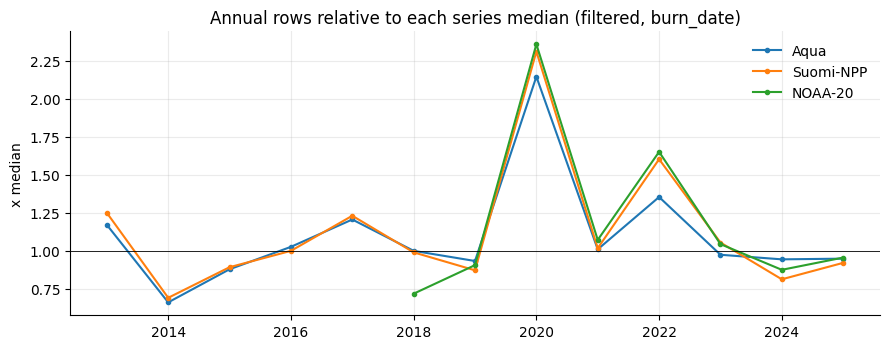

In [14]:
# Fire-days instead of rows: does the Aqua / Suomi-NPP agreement improve?
fd = nat.pivot_table(index='y', columns='satellite', values='fire_days', aggfunc='sum').loc[2013:2025]
rw = nat.pivot_table(index='y', columns='satellite', values='rows_', aggfunc='sum').loc[2013:2025]
print('Spearman Aqua vs Suomi-NPP over 2013-2025: rows %.3f, fire-days %.3f' % (stats.spearmanr(rw.Aqua, rw['Suomi-NPP'])[0], stats.spearmanr(fd.Aqua, fd['Suomi-NPP'])[0]))
print('Suomi-NPP / Aqua ratio, median over years: rows %.2f, fire-days %.2f' % ((rw['Suomi-NPP'] / rw.Aqua).median(), (fd['Suomi-NPP'] / fd.Aqua).median()))
fig, ax = plt.subplots(figsize=(9, 3.6))
for s, c in [('Aqua', 'tab:blue'), ('Suomi-NPP', 'tab:orange'), ('NOAA-20', 'tab:green')]:
    z = rw[s].where(rw[s] > 0); ax.plot(z.index, z / z.median(), marker='o', ms=3, color=c, label=s)
ax.axhline(1, color='k', lw=.6); ax.set(title='Annual rows relative to each series median (filtered, burn_date)', ylabel='x median'); ax.legend(frameon=False); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

**Reading.**

- **Sensor.** Aqua and Suomi-NPP agree on the ranking of years (Spearman 0.93 for both countries together and for Argentina, 0.68 for Chile). **2020** is the most active year in every sensor for both countries together, and the top 3 for Argentina are 2013, 2020 and 2022 in both.
  In Chile the top 3 are **2015, 2017 and 2023** for Aqua and Suomi-NPP. Terra and Aqua agree for Argentina (0.99) but not for Chile (0.36): Chile has few rows per year, so its ranking is more fragile.
- **Months.** Aqua and Suomi-NPP agree on year-months (Spearman 0.96 for 156 months); they share 7 of the top 10 for Argentina and 5 for Chile. The top 2 months nationally are August and September 2020 in both.
- **Filter and day convention do not change the ranking.** No filter against filtered: Spearman 0.97 to 0.999 for Aqua and Suomi-NPP, in both countries (the lowest values are in Chile, where counts are small). UTC date against `burn_date`: 0.995 to 1.000. Only 0.96% of Suomi-NPP rows change month between the two.
  The choice of `burn_date` matters for daily series and for the weekday, not for months and years.
- **Calendar year against season.** The label matters and depends on the country. In Chile the season (July to June, labelled by its end year) and the calendar year give the same top 3 (Spearman 0.88 for Suomi-NPP, 0.82 for Aqua) because the fire season is in January to March.
  In Argentina the August to October peak falls in one calendar year and is split by a July to June season (Spearman 0.45 for Suomi-NPP, 0.68 for Aqua; top years 2021, 2022, 2023 against 2013, 2020, 2022): **for Argentina the calendar year is the natural fire year**.
  The app should show the calendar year by default and the season as an option, and say which one it uses next to every ranking.
- **Fire-days against rows.** Rank agreement is similar (0.945 against 0.934), but the Suomi-NPP / Aqua ratio is 2.7 for fire-days against 4.9 for rows: fire-days remove most of the sensor difference in size (as the earlier estimate of 2.8 for 2019-2021), which makes it a good candidate metric for block 3.

## 4.6 Afternoon and night share, and the weekly cycle

Pass slot from local solar time (UTC hour + longitude / 15): `day_pass` from 06:00 to 18:00, otherwise `night_pass`.
The weekly cycle uses `burn_date`: the afternoon pass falls on the same civil day, so its weekday is the civil weekday (the night pass can belong to the previous civil day, so it is left out).
Fire-days are used so that one fire with many pixels does not weigh more than another.

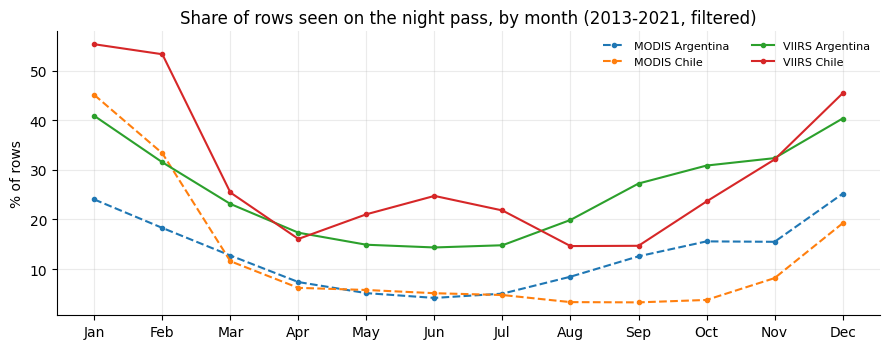

Night share, all months (2013-2021):


night %
instrument country           
MODIS      Argentina     12.4
           Chile         19.8
VIIRS      Argentina     25.0
           Chile         34.1

In [15]:
slot = q('''SELECT instrument, satellite, country, month(burn_date) mo, year(burn_date) y,
  CASE WHEN ((hour(ts) + minute(ts) / 60.0 + longitude / 15.0) % 24 + 24) % 24 BETWEEN 6 AND 18 THEN 'day_pass' ELSE 'night_pass' END pass_slot, count(*) n
  FROM base WHERE year(burn_date) BETWEEN 2013 AND 2021 GROUP BY ALL''')
sh = slot.groupby(['instrument', 'country', 'mo', 'pass_slot']).n.sum().unstack()
sh['night_share'] = sh.night_pass / (sh.night_pass + sh.day_pass)
piv = sh.night_share.unstack(['instrument', 'country'])
fig, ax = plt.subplots(figsize=(9, 3.6))
for (inst, c), s in piv.items(): ax.plot(MN, 100 * s.values, marker='o', ms=3, ls='-' if inst == 'VIIRS' else '--', label=f'{inst} {c}')
ax.set(title='Share of rows seen on the night pass, by month (2013-2021, filtered)', ylabel='% of rows'); ax.legend(frameon=False, fontsize=8, ncol=2); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()
print('Night share, all months (2013-2021):'); display((100 * slot.groupby(['instrument', 'country']).apply(lambda g: g[g.pass_slot == 'night_pass'].n.sum() / g.n.sum(), include_groups=False)).round(1).rename('night %').to_frame())

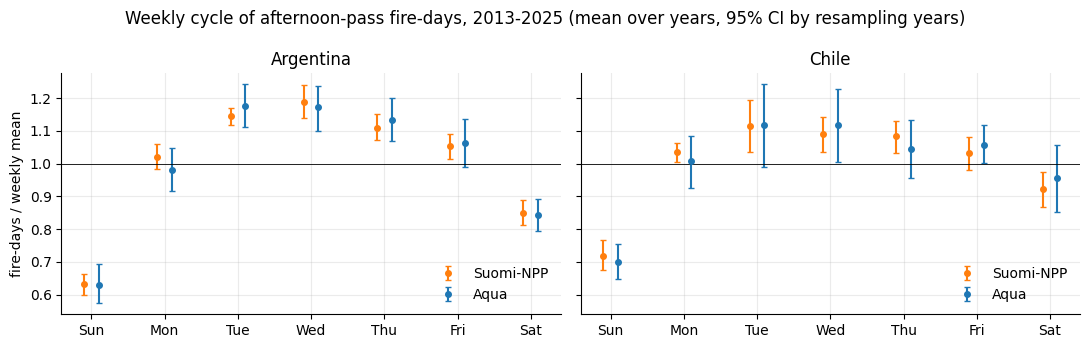

,country,satellite,Sun,Mon,Tue,Wed,Thu,Fri,Sat
0,Argentina,Suomi-NPP,0.632,1.022,1.145,1.188,1.109,1.054,0.850
1,Argentina,Aqua,0.630,0.981,1.175,1.173,1.133,1.063,0.844
2,Chile,Suomi-NPP,0.719,1.036,1.114,1.091,1.085,1.033,0.922
3,Chile,Aqua,0.699,1.009,1.116,1.117,1.045,1.056,0.957


In [16]:
wk = q('''SELECT country, satellite, year(burn_date) y, dayofweek(burn_date) dow, count(DISTINCT (cy, cx, burn_date)) fire_days FROM base
  WHERE satellite IN ('Suomi-NPP', 'Aqua') AND year(burn_date) BETWEEN 2013 AND 2025
  AND ((hour(ts) + minute(ts) / 60.0 + longitude / 15.0) % 24 + 24) % 24 BETWEEN 6 AND 18 GROUP BY ALL''')
DOW = ['Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat']
rng = np.random.default_rng(7)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True); out = []
for a, c in zip(ax, ['Argentina', 'Chile']):
    for sat, col in [('Suomi-NPP', 'tab:orange'), ('Aqua', 'tab:blue')]:
        p = wk[(wk.country == c) & (wk.satellite == sat)].pivot_table(index='y', columns='dow', values='fire_days', fill_value=0).reindex(columns=range(7), fill_value=0)
        prof = p.div(p.mean(axis=1), axis=0)                      # each year: weekday / mean weekday of that year
        boot = np.array([prof.iloc[rng.integers(0, len(prof), len(prof))].mean().values for _ in range(2000)])
        m = prof.mean().values; lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
        a.errorbar(np.arange(7) + (.1 if sat == 'Aqua' else -.1), m, yerr=[m - lo, hi - m], fmt='o', ms=4, capsize=2, color=col, label=sat)
        out.append(dict(country=c, satellite=sat, **{DOW[i]: round(m[i], 3) for i in range(7)}))
    a.axhline(1, color='k', lw=.6); a.set_xticks(range(7)); a.set_xticklabels(DOW); a.set_title(c); a.grid(alpha=.25); a.legend(frameon=False)
ax[0].set_ylabel('fire-days / weekly mean'); fig.suptitle('Weekly cycle of afternoon-pass fire-days, 2013-2025 (mean over years, 95% CI by resampling years)'); plt.tight_layout(); plt.show()
display(pd.DataFrame(out))

**Reading.**

- **Night pass.** VIIRS sees 25% of its rows on the night pass in Argentina and 34% in Chile; MODIS sees 12% and 20%. The night share is higher in Chile than in Argentina and higher for VIIRS than for MODIS.
  The sensors do not see the same mix of day and night detections, so a single ratio per sensor would mix two populations: block 3.2 should estimate it per `pass_slot`.
- **Weekly cycle.** Fire-days of the afternoon pass drop on weekends in both countries and in both sensors: **Sunday is 37% below the weekly mean in Argentina** (0.63) and 28 to 30% below in Chile (0.70 to 0.72); Saturday is 15% below in Argentina and 4 to 8% below in Chile.
  Tuesday to Thursday are 4 to 19% above. Suomi-NPP and Aqua give the same profile with overlapping intervals, so it is not an artefact of one sensor.
  Natural fires do not follow the week, so this is consistent with a large share of burning started or managed by people (agriculture, waste, land clearing). It does not say which fires are legal or intentional.

## 4.7 Trends, within one sensor and one stable period

A trend over the whole record would mix real change with changes of the instrument. So each trend is computed **inside one satellite and its stable period**:
Terra 2001-2021 (before its drift), Aqua 2003-2022, Suomi-NPP 2013-2025, NOAA-20 2019-2025 (full years), plus Aqua and Suomi-NPP over the **same** years 2013-2022 to compare the two sensors on equal terms. Method: Theil-Sen slope of annual rows, in % of the series median per year,
with a 95% interval from resampling the years, and Kendall's tau. No harmonized trend is claimed here: that needs M2 and the period controls of E1 to E6.

,metric,satellite,years,median,slope_pct_per_year,ci_low,ci_high,kendall_tau,p_value
0,rows,Terra,2001-2021,26544,-2.4,-3.9,-1.3,-0.41,0.009
1,rows,Aqua,2003-2022,45669,-2.9,-4.8,-1.1,-0.39,0.016
2,rows,Suomi-NPP,2013-2025,180711,0.3,-2.9,5.7,0.03,0.952
3,rows,NOAA-20,2019-2025,180125,-4.2,-36.3,5.6,-0.33,0.381
4,rows,Aqua,2013-2022,37963,4.0,-1.3,15.3,0.33,0.216
5,rows,Suomi-NPP,2013-2022,182279,4.6,-1.7,16.5,0.29,0.291
6,fire_days,Terra,2001-2021,11836,-2.1,-3.6,-0.4,-0.31,0.049
7,fire_days,Aqua,2003-2022,19025,-2.9,-4.2,-1.4,-0.42,0.009
8,fire_days,Suomi-NPP,2013-2025,43318,-0.1,-1.8,3.6,-0.03,0.952
9,fire_days,NOAA-20,2019-2025,44251,-3.6,-19.7,3.9,-0.24,0.562


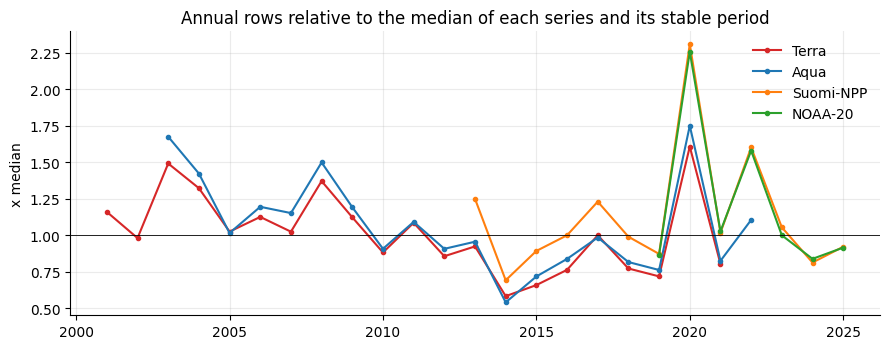

In [17]:
yrs = pd.DataFrame({s: nat[nat.satellite == s].groupby('y').rows_.sum() for s in ['Terra', 'Aqua', 'Suomi-NPP', 'NOAA-20']})
fyrs = pd.DataFrame({s: nat[nat.satellite == s].groupby('y').fire_days.sum() for s in ['Terra', 'Aqua', 'Suomi-NPP', 'NOAA-20']})
win = {'Terra': (2001, 2021), 'Aqua': (2003, 2022), 'Suomi-NPP': (2013, 2025), 'NOAA-20': (2019, 2025)}
common = {'Aqua': (2013, 2022), 'Suomi-NPP': (2013, 2022)}   # same years for both sensors
def theil_sen(x, y):
    sl = [(y[j] - y[i]) / (x[j] - x[i]) for i in range(len(x)) for j in range(i + 1, len(x))]; return np.median(sl)
rng = np.random.default_rng(11); res = []
for metric, tab in [('rows', yrs), ('fire_days', fyrs)]:
    for s, (a, b) in [*win.items(), *common.items()]:
        y = tab[s].loc[a:b].dropna(); x = y.index.values.astype(float); med = y.median(); yv = y.values / med
        sl = theil_sen(x, yv); tau, p = stats.kendalltau(x, yv)
        bs = []
        for _ in range(2000):
            k = np.sort(rng.integers(0, len(x), len(x)))
            if len(set(x[k])) < 3: continue
            bs.append(theil_sen(x[k][np.unique(x[k], return_index=True)[1]], yv[k][np.unique(x[k], return_index=True)[1]]))
        lo, hi = np.percentile(bs, [2.5, 97.5])
        res.append(dict(metric=metric, satellite=s, years=f'{a}-{b}', median=int(med), slope_pct_per_year=round(100 * sl, 1), ci_low=round(100 * lo, 1), ci_high=round(100 * hi, 1), kendall_tau=round(tau, 2), p_value=round(p, 3)))
tr = pd.DataFrame(res); display(tr)
fig, ax = plt.subplots(figsize=(9, 3.6))
for s, (a, b), c in zip(win, win.values(), ['tab:red', 'tab:blue', 'tab:orange', 'tab:green']):
    y = yrs[s].loc[a:b]; ax.plot(y.index, y / y.median(), marker='o', ms=3, color=c, label=s)
ax.axhline(1, color='k', lw=.6); ax.set(title='Annual rows relative to the median of each series and its stable period', ylabel='x median'); ax.legend(frameon=False); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

**Reading.**

- **The sign of the trend depends on the window.** Inside the MODIS stable period, Terra 2001-2021 and Aqua 2003-2022 decrease by about 2.4 to 2.9% of their median per year, with intervals that exclude zero (Aqua rows: -2.9%, 95% interval -4.8 to -1.1).
  Suomi-NPP over 2013-2025 shows no trend (+0.3%, interval -2.9 to 5.7). NOAA-20 has 7 years: the interval (-36 to +6) says nothing.
- **On equal terms (2013-2022) the two sensors agree and the slope is positive**: Aqua +4.0% and Suomi-NPP +4.6% per year for rows (intervals -1.3 to 15.3 and -1.7 to 16.5, both include zero), fire-days +3.2% and +3.3%.
  The top years of Aqua's record are 2003 and 2008 (block 4.5), early in the long window, so the long-window slope is sensitive to where the window starts; it does not carry into the VIIRS era.
- We therefore **make no trend claim** for the app. A harmonized trend needs the harmonized series and the period controls of the plan (E1 without Aqua, the number of satellites, the Aqua and Terra drift after 2022). The drift is a reason to stop the MODIS windows at 2021-2022.

## 4.8 Handing the numbers to the app

`monthly_by_region.parquet` is the table of monthly rows and fire-days per region and satellite (filtered, `nrt_rows` marks provisional data). It is a stand-in until the harmonized dataset (C2) exists.
When M2 publishes `cells_daily.parquet`, the calendar needs three changes:

1. Replace `base` by the harmonized cells (`hotspots_harmonized` as the value, `burn_date` as the day key, `provisional` as the NRT flag) and re-run the aggregates.
2. Re-run 4.3 with the harmonized series and the full reference period (the 2013-2025 reference here is the VIIRS era only).
3. Re-check 4.5: after harmonization the ranking of years has to agree between the MODIS-based and the VIIRS-based part of the series.

The definitions the API needs (anomaly, percentile, reliability threshold, same-day cut) are written in `docs/findings/04-calendar.md`.

In [18]:
# Smoke test of the contract with the app: the month totals can be rebuilt from the saved file.
chk = pd.read_parquet(OUT / 'monthly_by_region.parquet')
a = chk.groupby('satellite').rows_.sum(); b = q("SELECT satellite, count(*) n FROM base WHERE region IS NOT NULL GROUP BY 1").set_index('satellite').n
print('file totals equal the filtered table:', bool((a == b.reindex(a.index)).all()))
print('range:', chk.y.min(), '-', chk.y.max(), '| provisional rows:', int(chk.nrt_rows.sum()))

file totals equal the filtered table: True
range: 2000 - 2026 | provisional rows: 134070
